# Pertemuan 11 — Praktikum 4: Klasifikasi Citra Wajah

Praktikum ini mengklasifikasikan citra wajah publik figur menggunakan SVM dengan pra pengolahan *Principal Component Analysis* (PCA) dan *hyperparameter tuning* melalui GridSearchCV.

NB: Pengunduhan dataset melalui `fetch_lfw_people` dapat memerlukan waktu yang cukup lama.

Sumber: [Praktikum 4](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2/praktikum-4).

## 1. Langkah 0 — Unduh Dataset

Dataset wajah diunduh langsung dari Scikit-Learn dengan `min_faces_per_person=60`.

In [1]:
from sklearn.datasets import fetch_lfw_people

faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


## 2. Langkah 1 — Inspeksi Citra Wajah

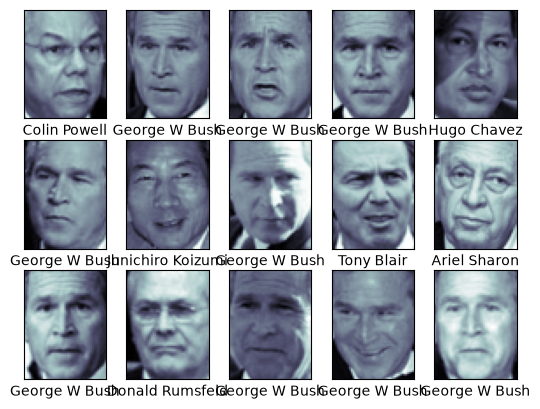

In [2]:
%matplotlib inline
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.show()

## 3. Langkah 2 — Pra Pengolahan dengan PCA

PCA mereduksi dimensi citra ke sejumlah *principal component* (150) agar lebih efisien. PCA dan SVC dirangkai dalam sebuah pipeline.

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline menjalankan PCA lalu SVC dalam satu fungsi
model = make_pipeline(pca, svc)

## 4. Langkah 3 — Split Data

In [4]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(
    faces.data, faces.target, random_state=42)

## 5. Langkah 4 — Pembuatan Model + Tuning (GridSearchCV)

GridSearchCV mencoba kombinasi hyperparameter `C` dan `gamma` untuk menemukan nilai terbaik.

In [5]:
from sklearn.model_selection import GridSearchCV

param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 10.2 s, sys: 983 ms, total: 11.2 s
Wall time: 11.3 s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Model terbaik hasil GridSearch digunakan untuk memprediksi data uji.

In [6]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

## 6. Langkah 5 — Cek Hasil Prediksi pada Citra

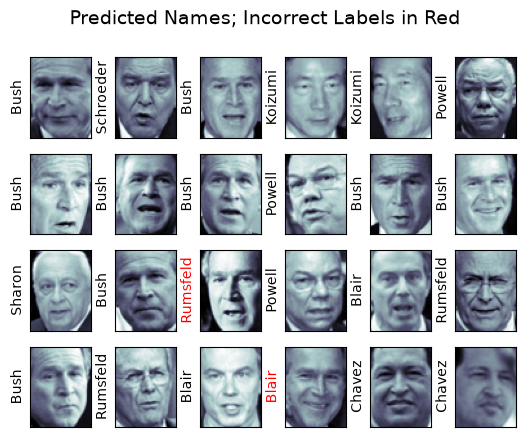

In [7]:
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)
plt.show()

## 7. Langkah 6 — Cek Performansi

Performa diukur dengan *classification report* dan *confusion matrix*.

In [8]:
from sklearn.metrics import classification_report

print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



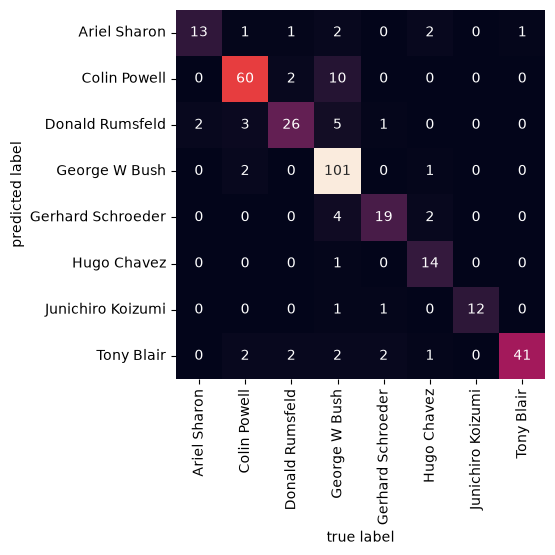

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.show()